In [1]:
import sys
sys.path.insert(1, '/home/santolam/MyPythonLibrary/MAR-RECAP/libmar/')
import climbasis as climb
from climbasis import *
import domain as dom
import myplot
import numpy.ma as ma
from myplot import *
import obsinfo as obs
from obsinfo import *



In [2]:
#domainM='GRq'; nx=ny=10
#domainM='GRq'
#ds_TTZ_raw=xr.open_mfdataset('/bettik/PROJECTS/pr-regional-climate/santolam/MARout_post/GRq/spin2/work/daily/'+
#    'TTZ_daymean_MARv3.14_ER5_spin2_GRq_*.nc')['TTZ'].sel(ZTQLEV=2)
#ds_TTZ= ds_TTZ_raw.rename({'TIME': 'time'})
#ds_TTZ=ds_TTZ[:,ny:-ny,nx:-nx]

In [3]:
plotsDir='/home/santolam/MyPythonLibrary/MAR-RECAP/scripts_paper_on_evaluation_MAR/figures_paper_on_evaluation/'

In [4]:
resultsDir='/home/santolam/MyPythonLibrary/MAR-RECAP/scripts_paper_on_evaluation_MAR/compu_results/'

In [6]:
##GLACIOCLIM
####
##Donnes meteo
sourceData='/bettik/PROJECTS/pr-regional-climate/santolam/glacioclim/donnees_meteo/'
#
##
#Pyramid
#5035 m a.s.l (off-glacier)	2019 à 2024 X
#
#Mera La ML
#5350 m a.s.l (off-glacier)	2013 à 2024 X
#Mera 5770 M5
#5770 m a.s.l (on-glacier)	2017 à 2024
#Mera Naulek MN
#5350 m a.s.l (on-glacier)	2012 à 2024 X
#Mera Summit MS
#6350 m a.s.l (on-glacier)	2013 à 2016 X


In [7]:
#West Changri Nup
#5360 m a.s.l (on-glacier)	2010 à 2012
#2012 à 2014
#2014 à 2024
#North Changri Nup
#5470 m a.s.l (on-glacier)	2014 à 2017

In [8]:
fileName='AWS_Pyramid_2019_2024.xlsx'
lat_PYG= 27.95892;lon_PYG=86.812987;elev_PYG=5035 

xl_file_PYG= pd.ExcelFile(sourceData+fileName)
dfs_PYG = {sheet_name: xl_file_PYG.parse(sheet_name) 
          for sheet_name in xl_file_PYG.sheet_names}
File_PYG=dfs_PYG['Pyramid_2019_24']
UnitVars_PYG=['(°C)','(%)','Dist sensor-surf','Dist sensor-surf','(m/s)','AWS (°)','(m/s)','(hPa)','(W/m2)',
              '(W/m2)','(W/m2)','(W/m2)','(mm)','(°C)','(%)','(m/s)', 'Geonor (°)','(m/s)','(mm)','(mm)','(mm)']
NameVars_PYG=['Time','Tair_AWS','RH_AWS','Abl_Acc','Abl_Acc','u_AWS','Direction','u_max_AWS','Patm','SWin','SWout','LWin_cor','LWout_cor','Geonor','Tair_Geonor','RH_Geonor','u_Geonor',
              'Direction','u_max_Geonor','Geonor','Geonor','Geonor']

dfile_PYG = pd.DataFrame(data=File_PYG.loc[5:])
df_PYG=pd.DataFrame(dfile_PYG.values, columns=NameVars_PYG)
#print(df_PYG.head())

time_clean = pd.to_datetime(df_PYG["Time"], errors="coerce").values
NameVar = "tair"

ds_PYG_tair = xr.Dataset(
    data_vars={NameVar: ("time", df_PYG["Tair_AWS"].astype(float).values)},
    coords={"time": time_clean})
tt_daily_PYG_raw = ds_PYG_tair.resample(time='1D').mean()
#ds_daily = ds_PYG_tair.resample(time='1D').max()
#ds_daily = ds_PYG_tair.resample(time='1D').min()
#ds_daily = ds_PYG_tair.resample(time='1D').sum()
tt_daily_PYG=tt_daily_PYG_raw.tair

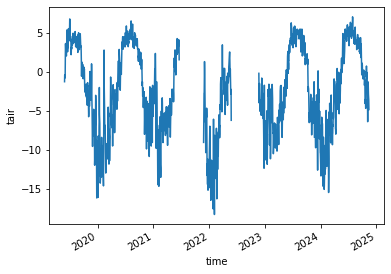

In [9]:
tt_daily_PYG.plot()

In [10]:
##MeraLafinal2013_24.xlsx
###
#AWS-Mera La: Since November 2013 (AWS inserted on firm rocks – off-glacier)
#Location in WGS84, Lat: 27.735°N; Long: 86.900°E; Elevation: 5352.008 m 
#or UTM Zone 45; Easting: 490137.007 m; Northing: 3067850.613 m on 22/11/2020
###

fileName='MeraLafinal2013_24.xlsx'

xl_file_MeraLa = pd.ExcelFile(sourceData+fileName)

dfs_MeraLa = {sheet_name: xl_file_MeraLa.parse(sheet_name) 
          for sheet_name in xl_file_MeraLa.sheet_names}
File_MeraLa=dfs_MeraLa['MeraLa2013_23']

NameVars_MeraLa=['Time','Tair','RH','u','Direction','SWin','SWout','LWin','LWout','Patm']
UnitVars_MeraLa=['data/hour','C','%','m/s','degrees','W/m2','W/m2','W/m2','W/m2','hPa']

##Define new DataFrame and changing name of columns
dfile_MeraLa = pd.DataFrame(data=File_MeraLa.loc[4:])
df_MeraLa=pd.DataFrame(dfile_MeraLa.values, columns=NameVars_MeraLa)

df_MeraLa.head()
### Opening one column + converting into an array
Tair_ar=[float(i) for i in df_MeraLa.Tair.values]

NameVar="Tair"; Var_ar=Tair_ar

start, end = df_MeraLa.Time.values[0], df_MeraLa.Time.values[-1]
time = pd.date_range(start, end, freq='30min')
ds_MeraLa = xr.Dataset({NameVar: ("time",np.asarray(Var_ar)), "time": time})

tt_daily_ML = ds_MeraLa.Tair.resample(time='D').mean()


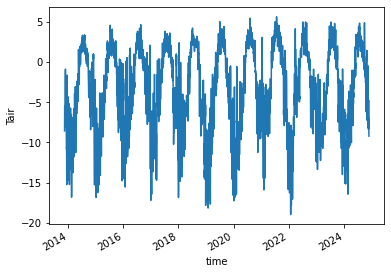

In [11]:
tt_daily_ML.plot()

In [12]:
##Mera Naulek
def NewTime(df,NameVar, Var_ar, freq):
    start = df.Time.values[0]
    time = pd.date_range(start=start, periods=len(Var_ar), freq=freq)
    ds = xr.DataArray(Var_ar, dims='time', coords={'time': time}, name=NameVar)
    return ds

fileName='Naulekfinal2012_24.xlsx'

xl_file_MeraNaulek = pd.ExcelFile(sourceData+fileName)

dfs_MeraNaulek = {sheet_name: xl_file_MeraNaulek.parse(sheet_name) 
          for sheet_name in xl_file_MeraNaulek.sheet_names}

File_MeraNaulek=dfs_MeraNaulek['Naulekfinal2012_24']

NameVars_MeraNaulek=['Time','Tairlow','RHlow','Tairhigh','RHhight','u','Direction','SWin','SWout','LWincor','LWoutcor','Abl/acc dist sensor surf','tilt metter XAXIS','tilt meter YAXIX']
UnitVars_MeraNaulek=['data/hour','C','%','C','%','m/s','degrees','W/m2','W/m2','W/m2','W/m2','m','degrees','degrees']


##Define new DataFrame and changing name of columns
dfile_MeraNaulek = pd.DataFrame(data=File_MeraNaulek.loc[4:])
df_MeraNaulek=pd.DataFrame(dfile_MeraNaulek.values, columns=NameVars_MeraNaulek)
### Opening one column + converting into an array
Tairlow_ar=[float(i) for i in df_MeraNaulek.Tairlow.values]   #Convertit les données en float utilisables 
Tairhigh_ar=[float(i) for i in df_MeraNaulek.Tairhigh.values] 
    
ds_Tlow_MeraNaulek=NewTime(df_MeraNaulek,'Tairlow',Tairlow_ar,'30min')
ds_Thigh_MeraNaulek=NewTime(df_MeraNaulek,'Tairhigh',Tairhigh_ar,'30min')
tlow_daily_mean_MeraNaulek  = ds_Tlow_MeraNaulek.resample(time='D').mean()
thigh_daily_mean_MeraNaulek  = ds_Thigh_MeraNaulek.resample(time='D').mean()



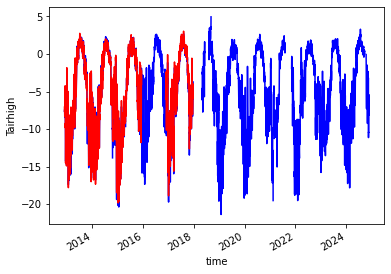

In [13]:
tlow_daily_mean_MeraNaulek.plot(color='blue')
thigh_daily_mean_MeraNaulek.plot(color='red')

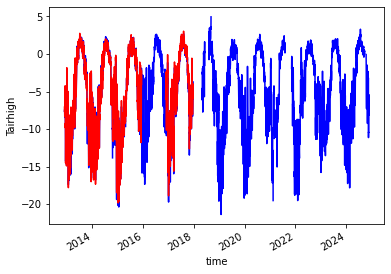

In [14]:
tlow_aligned, thigh_aligned = xr.align(
    tlow_daily_mean_MeraNaulek,
    thigh_daily_mean_MeraNaulek,
    join="inner"
)
tlow_aligned.plot(color='blue')
thigh_aligned.plot(color='red')

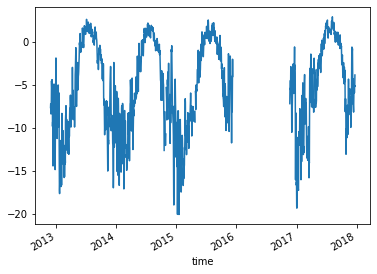

In [15]:
tmean = (tlow_aligned + thigh_aligned) / 2
tmean.plot()

In [16]:
tt_daily_MN=tmean
tmean.time[-1]

<xarray.DataArray 'time' ()>
array('2024-11-26T00:00:00.000000000', dtype='datetime64[ns]')
Coordinates:
    time     datetime64[ns] 2024-11-26

In [17]:
## Mera Summit

fileName='MeraSummit_2013-16.xlsx'

xl_file_MeraSummit = pd.ExcelFile(sourceData+fileName)

df_MeraSummit= {sheet_name: xl_file_MeraSummit.parse(sheet_name)     
       for sheet_name in xl_file_MeraSummit.sheet_names}
Data_MeraSummit=df_MeraSummit['MeraSummit2013_16']                  
NameVars_MeraSummit=['Time','Tairlow','RHlow','Tairhigh','RHhight','u','Direction','SWin','SWout','LWincor','LWoutcor','T1snow','T2snow','T3snow','T4snow','T5snow','T6snow','Abl/acc dist sensor surf','Quality number SR50','Patm']
UnitVars_MeraSummit=['data/hour','C','%','C','%','m/s','degrees','W/m2','W/m2','W/m2','W/m2','C','C','C','C','C','C','m','','hPa']

##Define new DataFrame and changing name of columns
dfile_MeraSummit= pd.DataFrame(data=Data_MeraSummit.loc[4:]) 
df_MeraSummit=pd.DataFrame(dfile_MeraSummit.values, columns=NameVars_MeraSummit) 

### Opening one column + converting into an array
Tairlow_ar_MeraSummit=[float(i) for i in df_MeraSummit.Tairlow.values]   #Convertit les données en float utilisables 
Tairhigh_ar_MeraSummit=[float(i) for i in df_MeraSummit.Tairhigh.values] 


ds_Tlow_MeraSummit = NewTime(df_MeraSummit,'Tairlow', Tairlow_ar_MeraSummit, '30min')
ds_Thigh_MeraSummit = NewTime(df_MeraSummit,'Tairhigh', Tairhigh_ar_MeraSummit, '30min')
ds_Tmean_MeraSummit = (ds_Tlow_MeraSummit + ds_Thigh_MeraSummit) / 2
ds_Tmean_MeraSummit.name = 'Tairmean'  # optional, rename variable

tlow_daily_mean_MeraSummit  = ds_Tlow_MeraSummit.resample(time='D').mean()
thigh_daily_mean_MeraSummit  = ds_Thigh_MeraSummit.resample(time='D').mean()
tmean_daily_mean_MeraSummit  = ds_Tmean_MeraSummit.resample(time='D').mean()

tt_daily_MS=tmean_daily_mean_MeraSummit

In [18]:
fileName='Changri5360final2014_24.xlsx'

xl_file_CHA3= pd.ExcelFile(sourceData+fileName)
dfs_CHA3 = {sheet_name: xl_file_CHA3.parse(sheet_name) 
          for sheet_name in xl_file_CHA3.sheet_names}

File_CHA3=dfs_CHA3['Changri_5360_2014_23']

NameVars_CHA3 = ["Date","SWin","SWout","LWin","LWout","Tair","RH","Height/surf","u high","Direction",
                    "Flux -21cm","T1 -1cm","T2 -16cm","T3 -21cm","u low","Direction"]

dfile_CHA3= pd.DataFrame(data=File_CHA3.loc[12:])
df_CHA3=pd.DataFrame(dfile_CHA3.values, columns=NameVars_CHA3)
print(df_CHA3.head())
time_clean = pd.to_datetime(df_CHA3["Date"], errors="coerce").values
NameVar = "Tair"

ds_CHA3_tair = xr.Dataset(
    data_vars={NameVar: ("time", df_CHA3["Tair"].astype(float).values)},
    coords={"time": time_clean})
tt_daily_CHA3_raw = ds_CHA3_tair.resample(time='1D').mean()
tt_daily_CHA3=tt_daily_CHA3_raw.Tair

                 Date    SWin   SWout    LWin   LWout    Tair      RH  \
0 2014-11-30 13:00:00  805.12   156.7  29.026  215.88  3.2685  7.4238   
1 2014-11-30 13:30:00   759.9  147.56  195.46  379.23   3.251  7.1217   
2 2014-11-30 14:00:00   692.5  133.82  194.69  376.27  3.2897  7.5707   
3 2014-11-30 14:30:00  607.17  117.99  194.24  375.13  3.3542  7.3504   
4 2014-11-30 15:00:00  507.74  98.694  192.92  367.47  2.9335  7.2352   

  Height/surf u high Direction Flux -21cm T1 -1cm T2 -16cm T3 -21cm  u low  \
0       0.884  4.541     174.5     16.179  7.5551      NaN      NaN  4.022   
1        0.88  5.179     263.3     17.151  12.908  -3.1084  -4.2914  4.604   
2       0.875  4.239     191.5     17.638   10.97  -2.6814  -3.9885  3.804   
3       0.881   3.26     210.9     17.519  10.885  -2.3063  -3.7073  3.002   
4       0.878  3.778     175.8     16.894   9.797  -2.0093  -3.4627  3.478   

  Direction  
0     195.2  
1     293.5  
2     192.2  
3       263  
4     215.8  


In [19]:
idatePYG = str(tt_daily_PYG.time[0].values)[:10]
fdatePYG = str(tt_daily_PYG.time[-1].values)[:10]
              
idateML = str(tt_daily_ML.time[0].values)[:10]
fdateML = str(tt_daily_ML.time[-1].values)[:10]

idateMS = str(tt_daily_MS.time[0].values)[:10]
fdateMS = str(tt_daily_MS.time[-1].values)[:10]

idateMN = str(tt_daily_MN.time[0].values)[:10]
#fdateMN = str(tt_daily_MN.time[-1].values)[:10]
fdateMN = str(tlow_daily_mean_MeraNaulek.time[-1].values)[:10]

#idateMN = str(tt_daily_MN.time[0].values)[:10]
#fdateMN = str(tt_daily_MN.time[-1].values)[:10]

idateCHA3=str(tt_daily_CHA3.time[0].values)[:10]
fdateCHA3=str(tt_daily_CHA3.time[-1].values)[:10]

In [20]:
###Coordinates

In [21]:
import pandas as pd
from pyproj import Transformer

# Define the transformer (UTM Zone 45N → WGS84)
transformer = Transformer.from_crs("epsg:32645", "epsg:4326", always_xy=True)

# --- Coordinates conversions (you already have some precomputed) ---
# MN (Mera North)
eastingMN, northingMN = 489885, 3065938
lon_MN, lat_MN = transformer.transform(eastingMN, northingMN)
elev_MN = 5360

# CH (Changri)
lon_CHA3, lat_CHA3, elev_CHA3 = 86.77948450, 27.98336311, 5360

# ML (Merala)
lon_ML, lat_ML, elev_ML = 86.900, 27.735, 5352.008

# KH (Khare)
lon_KH, lat_KH, elev_KH = 86.8776142768303, 27.74424682282522, 4888

# PH (Pheriche)
lon_PH, lat_PH, elev_PH = 86.81972903284355, 27.895048949594884, 4260

# PY (Pyramid)
lon_PY, lat_PY, elev_PY = 86.81296905961787, 27.957821815535848, 5035

# MS (Mera South)
eastingMS, northingMS = 487553.653, 3064704.231
lon_MS, lat_MS = transformer.transform(eastingMS, northingMS)
elev_MS = 6351  # estimated same as MN, if not otherwise specified

# MC (Mera Central; high camp 5770)
eastingMC, northingMC = 488409.424, 3066148.049
lon_MC, lat_MC = transformer.transform(eastingMC, northingMC)
elev_MC = 5770

# --- Define metadata list ---
stations_info_glacioclim = [
    {"ID": "MN", "Name": "Mera Naulek", "Lat": lat_MN, "Lon": lon_MN, "Elev_m": elev_MN, "Timestep": "1h"},
    #{"ID": "CH", "Name": "Changri", "Lat": lat_CH, "Lon": lon_CH, "Elev_m": elev_CH, "Timestep": "1h"},
    {"ID": "ML", "Name": "Mera La", "Lat": lat_ML, "Lon": lon_ML, "Elev_m": elev_ML, "Timestep": "1h"},
    {"ID": "KH", "Name": "Khare", "Lat": lat_KH, "Lon": lon_KH, "Elev_m": elev_KH, "Timestep": "1h"},
    {"ID": "PH", "Name": "Pheriche", "Lat": lat_PH, "Lon": lon_PH, "Elev_m": elev_PH, "Timestep": "1h"},
    {"ID": "PY", "Name": "Pyramid", "Lat": lat_PY, "Lon": lon_PY, "Elev_m": elev_PY, "Timestep": "1h"},
    {"ID": "MS", "Name": "Mera Summir", "Lat": lat_MS, "Lon": lon_MS, "Elev_m": elev_MS, "Timestep": "1h"},
    {"ID": "MC", "Name": "Mera Camp 5770", "Lat": lat_MC, "Lon": lon_MC, "Elev_m": elev_MC, "Timestep": "1h"},
    {"ID": "PYG", "Name": "Pyramid-AWS", "Lat": lat_PYG, "Lon": lon_PYG, "Elev_m": elev_PYG, "Timestep": "1h"},
    {"ID": "CHA3", "Name": "CHA3", "Lat": lat_CHA3, "Lon": lon_CHA3, "Elev_m": elev_CHA3, "Timestep": "1h"},
]


# --- Create DataFrame ---
df_stations_glacioclim = pd.DataFrame(stations_info_glacioclim)

# Display neatly
print(df_stations_glacioclim.to_string(index=False, justify='center', col_space=12))


     ID           Name           Lat          Lon        Elev_m      Timestep  
      MN        Mera Naulek  27.717723    86.897390     5360.000        1h     
      ML            Mera La  27.735000    86.900000     5352.008        1h     
      KH              Khare  27.744247    86.877614     4888.000        1h     
      PH           Pheriche  27.895049    86.819729     4260.000        1h     
      PY            Pyramid  27.957822    86.812969     5035.000        1h     
      MS        Mera Summir  27.706566    86.873753     6351.000        1h     
      MC     Mera Camp 5770  27.719608    86.882420     5770.000        1h     
     PYG        Pyramid-AWS  27.958920    86.812987     5035.000        1h     
    CHA3               CHA3  27.983363    86.779484     5360.000        1h     


In [22]:
# --- Merge all station metadata into one unified dictionary ---
stations_all = {}

# Add Glacioclim AWS
for sta in stations_info_glacioclim:
    stations_all[sta["ID"]] = (sta["Lat"], sta["Lon"], "Glacioclim")

# Check summary
print(f"Total stations merged: {len(stations_all)}")
print(stations_all.keys())

Total stations merged: 9
dict_keys(['MN', 'ML', 'KH', 'PH', 'PY', 'MS', 'MC', 'PYG', 'CHA3'])


In [25]:
# Observations
stations_tt_daily_glacioclim = {
    "MeraLa": tt_daily_ML,
    "MeraSummit": tt_daily_MS,
    "MeraNaulek": tt_daily_MN,
    "Pyramid": tt_daily_PYG,
    "ChangriA3": tt_daily_CHA3
}



# Station elevations
elev_station_glacioclim = {
    "MeraLa": elev_ML,
    "MeraSummit": elev_MS,
    "MeraNaulek": elev_MN,
    "Pyramid": elev_PYG,
    "ChangriA3": elev_CHA3
}



 Saved: /home/santolam/MyPythonLibrary/MAR-RECAP/scripts_paper_on_evaluation_MAR/figures_paper_on_evaluation/support_FIGSX_timeseries_daily_tas.glacioclim_MAR.GRc.png


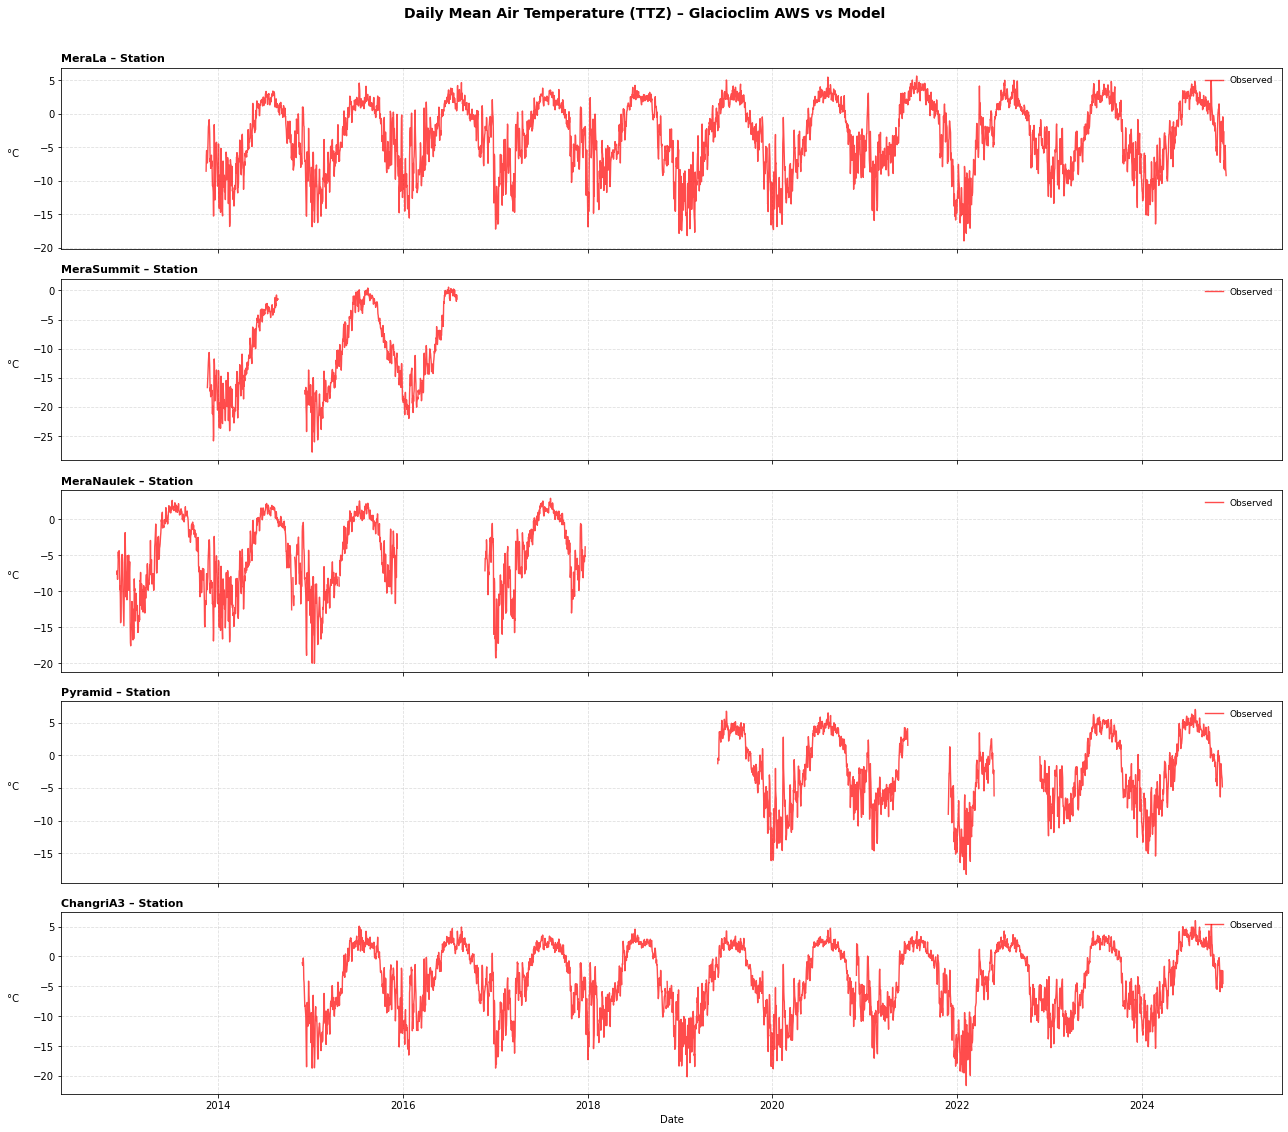

In [32]:
import matplotlib.pyplot as plt

# --- Observed daily mean temperature series ---
stations_tt_daily_glacioclim = {
    "MeraLa": tt_daily_ML,
    "MeraSummit": tt_daily_MS,
     "MeraNaulek": tt_daily_MN,
    "Pyramid": tt_daily_PYG,
    "ChangriA3": tt_daily_CHA3# optional, if available
}
# --- Create subplots (one per station) ---
fig, axes = plt.subplots(len(stations_tt_daily_glacioclim), 1, figsize=(18, 16), sharex=True)

# --- Plot each station ---
for ax, (name, obs_series) in zip(axes, stations_tt_daily_glacioclim.items()):
    # Observed daily temperature (line)
    ax.plot(obs_series.time.values, obs_series.values, color='red', lw=1.4, alpha=0.7, label="Observed")

      # Style + Title
    ax.set_ylabel("°C", rotation=0, labelpad=20)
    ax.set_title(f"{name} – Station",
                 loc='left', fontsize=11, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend(frameon=False, loc='upper right', fontsize=9)

# Shared labels and figure title
axes[-1].set_xlabel("Date")
fig.suptitle("Daily Mean Air Temperature (TTZ) – Glacioclim AWS vs Model",
             fontsize=14, fontweight='bold')

plt.tight_layout(rect=[0, 0, 1, 0.97])

plotname = f"support_FIGSX_timeseries_daily_tas.glacioclim_MAR.{domain}"
plt.savefig(f"{plotsDir}{plotname}.png", bbox_inches="tight", dpi=300)
print(f" Saved: {plotsDir}{plotname}.png")

plt.show()


In [35]:
import pandas as pd
import numpy as np

# =========================================================
# Function: seasonal mean ± std
# =========================================================

def seasonal_stats(series):

    seasons = {
        "DJFM": [12, 1, 2, 3],
        "AM": [4, 5],
        "JJAS": [6, 7, 8, 9],
        "ON": [10, 11]
    }

    stats = {}

    for season, months in seasons.items():

        data = series[series.index.month.isin(months)]

        mean = data.mean()
        std = data.std()

        stats[season] = f"{mean:.2f} ± {std:.2f}"

    return stats

# =========================================================
# Dates dictionary
# =========================================================

date_ranges = {
    "MeraLa": f"{idateML} to {fdateML}",
    "MeraSummit": f"{idateMS} to {fdateMS}",
    "MeraNaulek": f"{idateMN} to {fdateMN}",
    "Pyramid": f"{idatePYG} to {fdatePYG}",
    "ChangriA3": f"{idateCHA3} to {fdateCHA3}"
}

# =========================================================
# Build table
# =========================================================

rows = []

for station in stations_tt_daily_glacioclim.keys():

    # Observation series
    obs = stations_tt_daily_glacioclim[station].to_pandas()

    # Seasonal climatology
    clim_obs = seasonal_stats(obs)

    # Add row
    rows.append({

        "Station": station,

        "DJFM": clim_obs["DJFM"],

        "AM": clim_obs["AM"],

        "JJAS": clim_obs["JJAS"],

        "ON": clim_obs["ON"],
         "Period": date_ranges[station],
    })

# =========================================================
# Create DataFrame
# =========================================================

df_clim = pd.DataFrame(rows)

print(df_clim)

# =========================================================
# Save CSV
# =========================================================

outfile = f"{resultsDir}/seasonal_climatology_TTZ_glacioclim.csv"

df_clim.to_csv(outfile, index=False)

print(f"\nSaved: {outfile}")

      Station           DJFM             AM          JJAS            ON  \
0      MeraLa   -8.55 ± 4.00   -3.68 ± 2.56   1.94 ± 1.32  -3.65 ± 2.82   
1  MeraSummit  -17.90 ± 3.06  -11.19 ± 2.95  -2.49 ± 1.88  -9.75 ± 2.45   
2  MeraNaulek   -9.93 ± 3.88   -5.08 ± 2.78   0.38 ± 1.23  -6.43 ± 2.87   
3     Pyramid   -7.71 ± 3.78   -2.50 ± 2.84   3.79 ± 1.39  -2.87 ± 2.82   
4   ChangriA3   -9.79 ± 3.96   -4.23 ± 3.01   1.89 ± 1.23  -4.89 ± 3.05   

                     Period  
0  2013-11-15 to 2024-11-28  
1  2013-11-20 to 2016-08-02  
2  2012-11-27 to 2024-11-26  
3  2019-05-21 to 2024-11-13  
4  2014-11-30 to 2024-11-15  

Saved: /home/santolam/MyPythonLibrary/MAR-RECAP/scripts_paper_on_evaluation_MAR/compu_results//seasonal_climatology_TTZ_glacioclim.csv
